
══════════════════════════════════════════════════════════════════════
Client 1 — 257 samples
Region-Smoker group: northeast — no
Missing values:
 age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Descriptive statistics — Charges:
count      257.00
mean      9165.53
std       6157.20
min       1694.80
25%       4438.26
50%       8342.91
75%      11938.26
max      32108.66
Name: charges, dtype: float64

Categorical proportions:

sex:
sex
female    51.4
male      48.6
Name: proportion, dtype: float64%

smoker:
smoker
no    100.0
Name: proportion, dtype: float64%

region:
region
northeast    100.0
Name: proportion, dtype: float64%

Correlation of all features with charges (Client 1):
charges     1.000
age         0.568
bmi         0.182
children    0.121
sex_male   -0.079
Name: charges, dtype: float64

Client 1 — Mean: $9,166
Client 1 — Median: $8,343
Client 1 — Std: $6,157


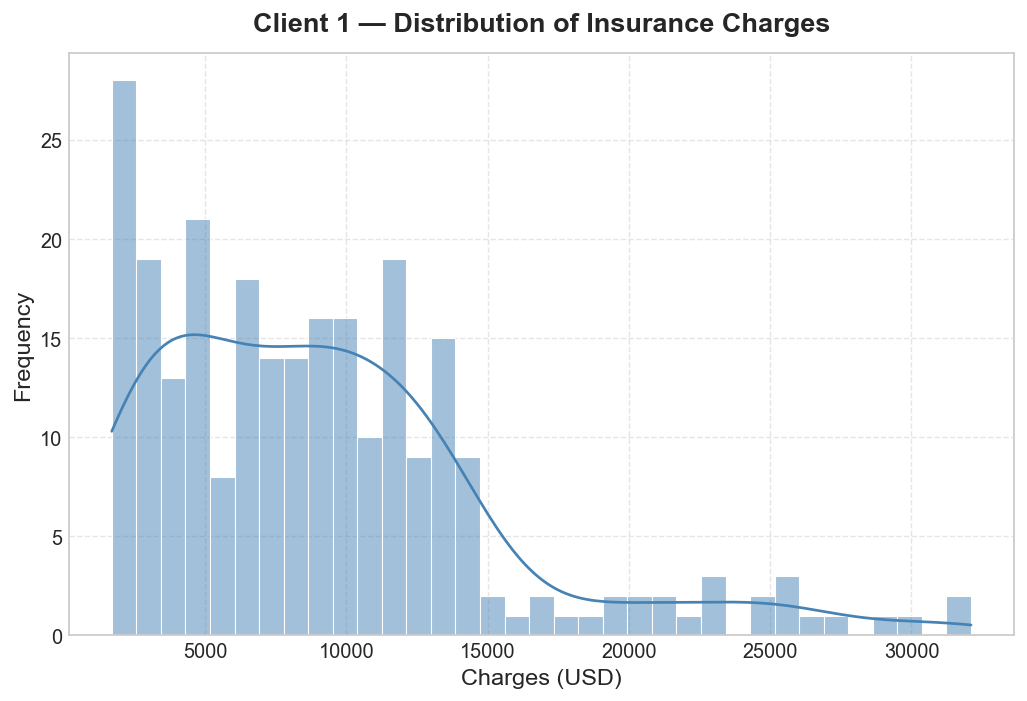

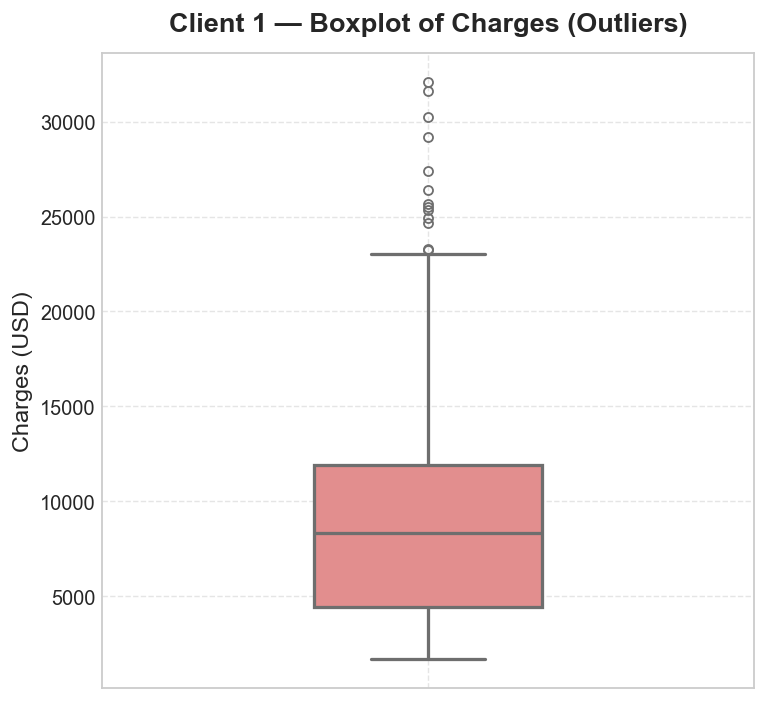

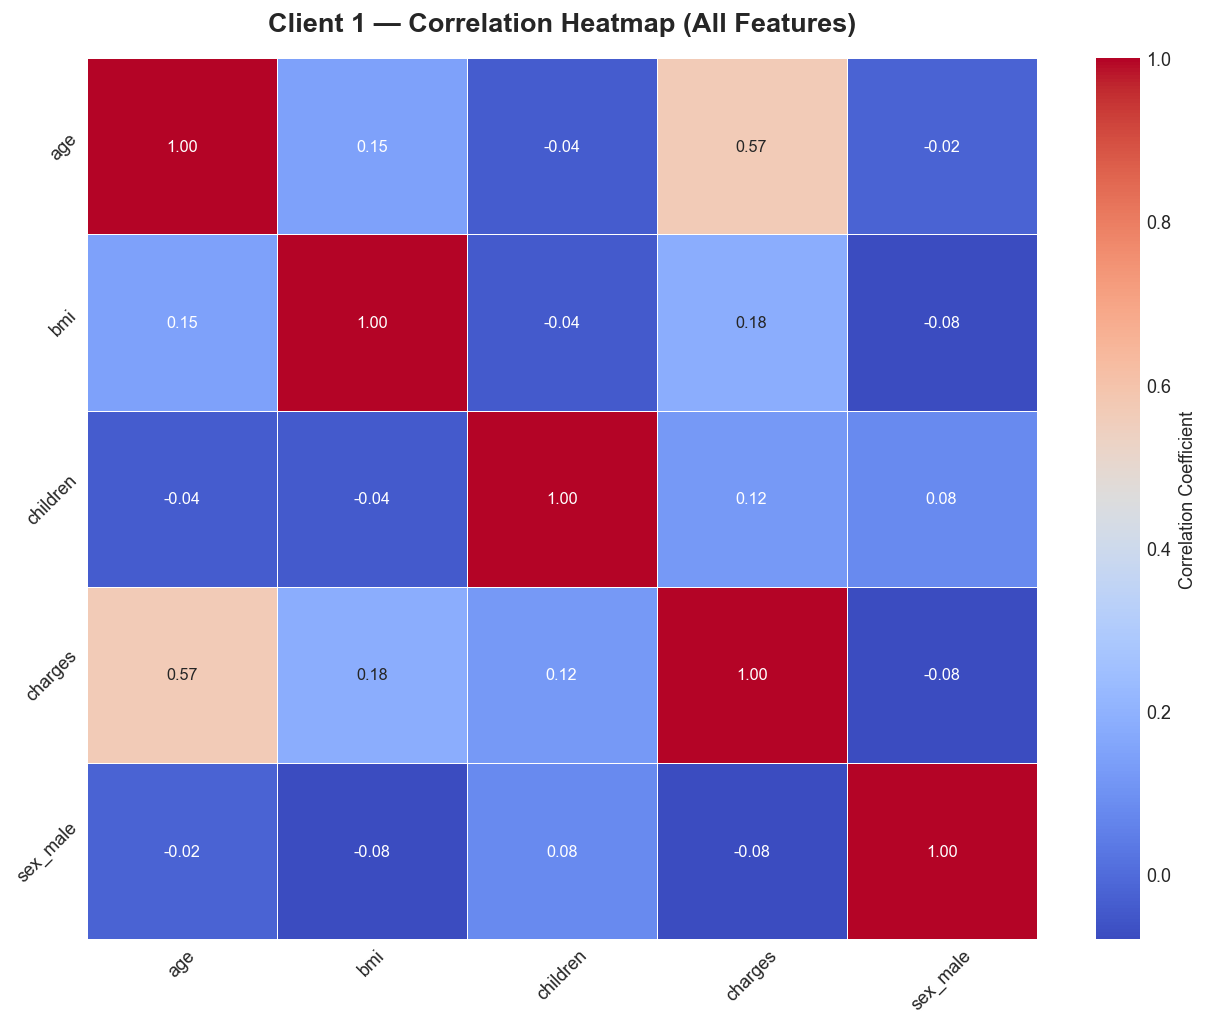


══════════════════════════════════════════════════════════════════════
Client 2 — 67 samples
Region-Smoker group: northeast — yes
Missing values:
 age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Descriptive statistics — Charges:
count       67.00
mean     29673.54
std      11589.56
min      12829.46
25%      19881.40
50%      28101.33
75%      39576.95
max      58571.07
Name: charges, dtype: float64

Categorical proportions:

sex:
sex
male      56.7
female    43.3
Name: proportion, dtype: float64%

smoker:
smoker
yes    100.0
Name: proportion, dtype: float64%

region:
region
northeast    100.0
Name: proportion, dtype: float64%

Correlation of all features with charges (Client 2):
charges     1.000
bmi         0.874
age         0.395
sex_male    0.125
children    0.077
Name: charges, dtype: float64

Client 2 — Mean: $29,674
Client 2 — Median: $28,101
Client 2 — Std: $11,590


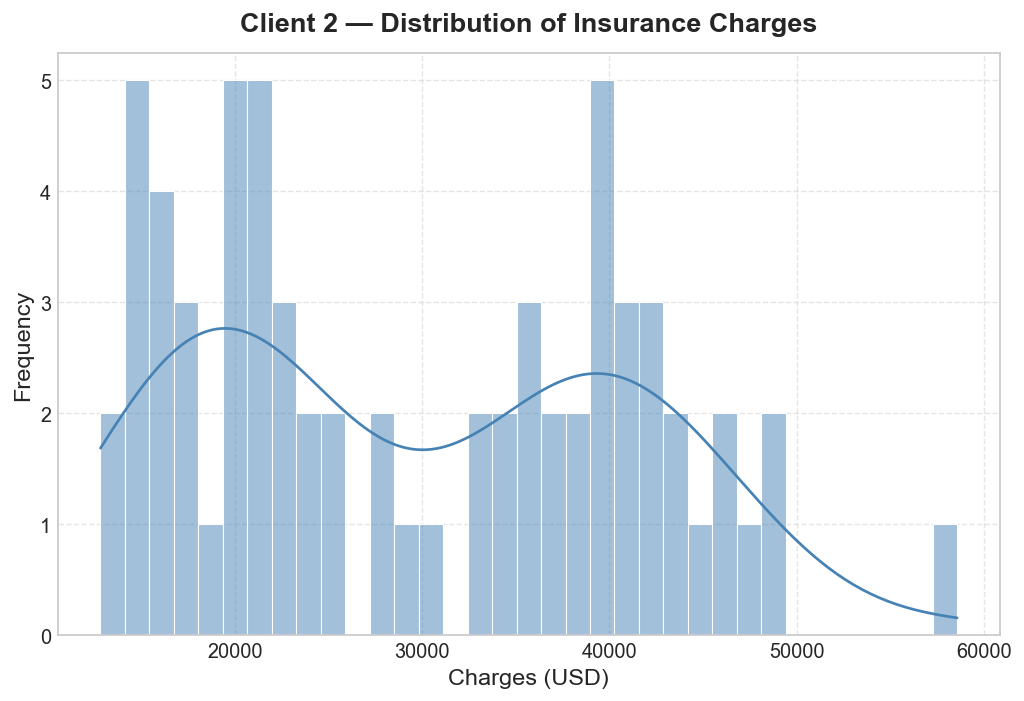

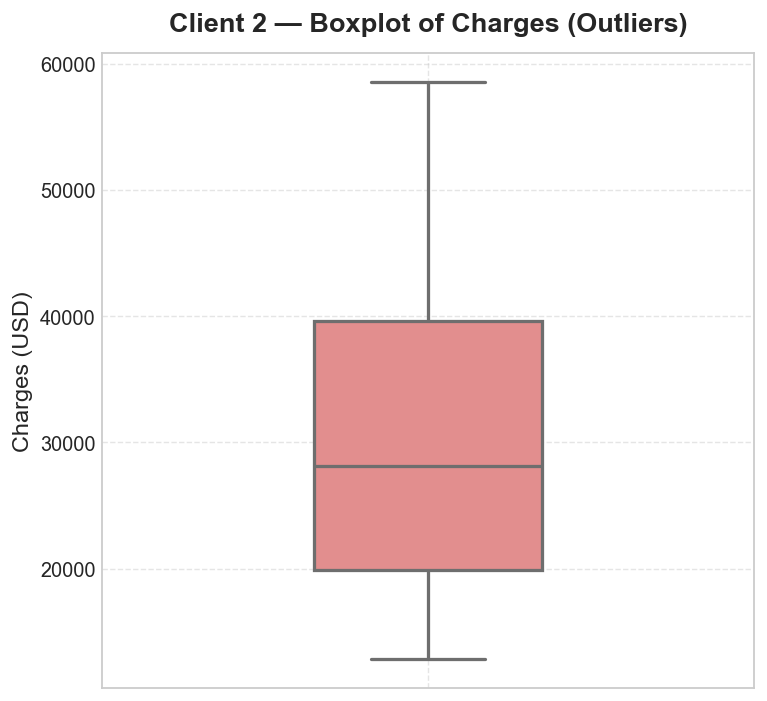

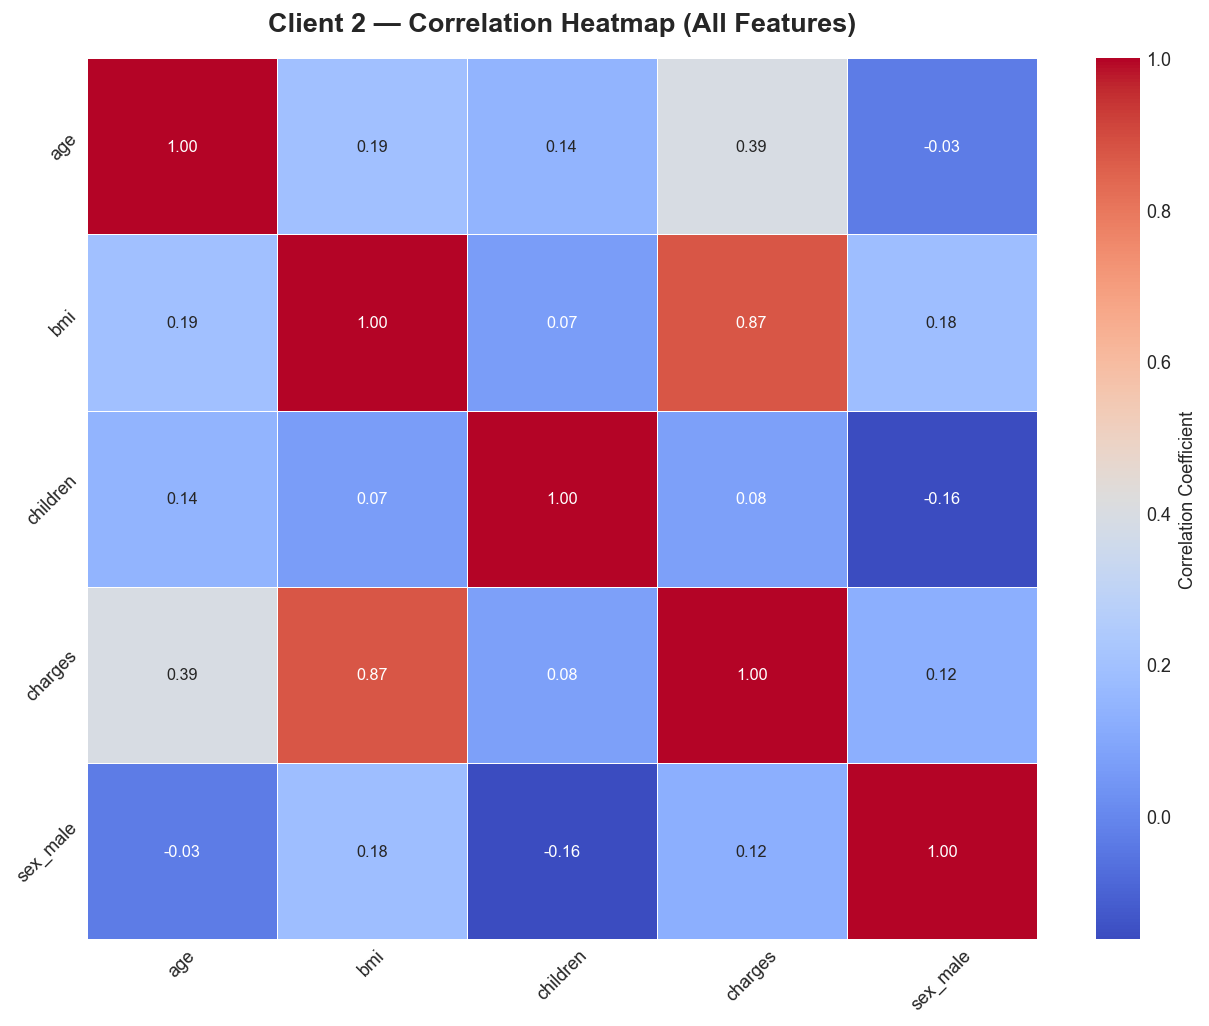


══════════════════════════════════════════════════════════════════════
Client 3 — 267 samples
Region-Smoker group: northwest — no
Missing values:
 age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Descriptive statistics — Charges:
count      267.00
mean      8556.46
std       6128.55
min       1621.34
25%       4161.60
50%       7256.72
75%      11354.94
max      33471.97
Name: charges, dtype: float64

Categorical proportions:

sex:
sex
female    50.6
male      49.4
Name: proportion, dtype: float64%

smoker:
smoker
no    100.0
Name: proportion, dtype: float64%

region:
region
northwest    100.0
Name: proportion, dtype: float64%

Correlation of all features with charges (Client 3):
charges     1.000
age         0.586
children    0.176
bmi         0.131
sex_male   -0.038
Name: charges, dtype: float64

Client 3 — Mean: $8,556
Client 3 — Median: $7,257
Client 3 — Std: $6,129


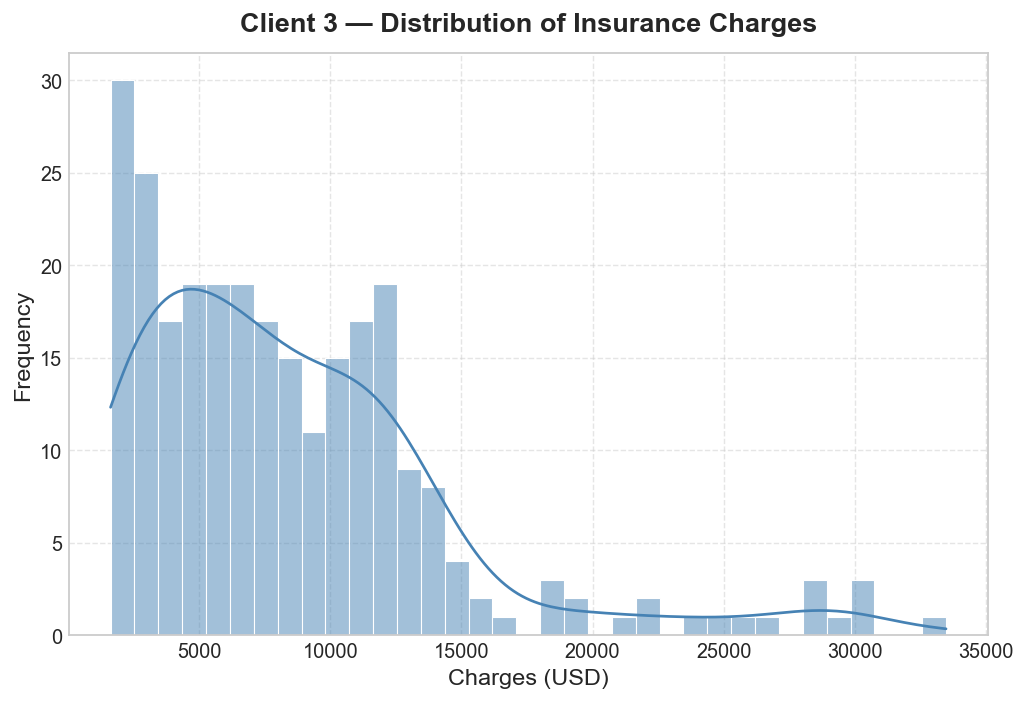

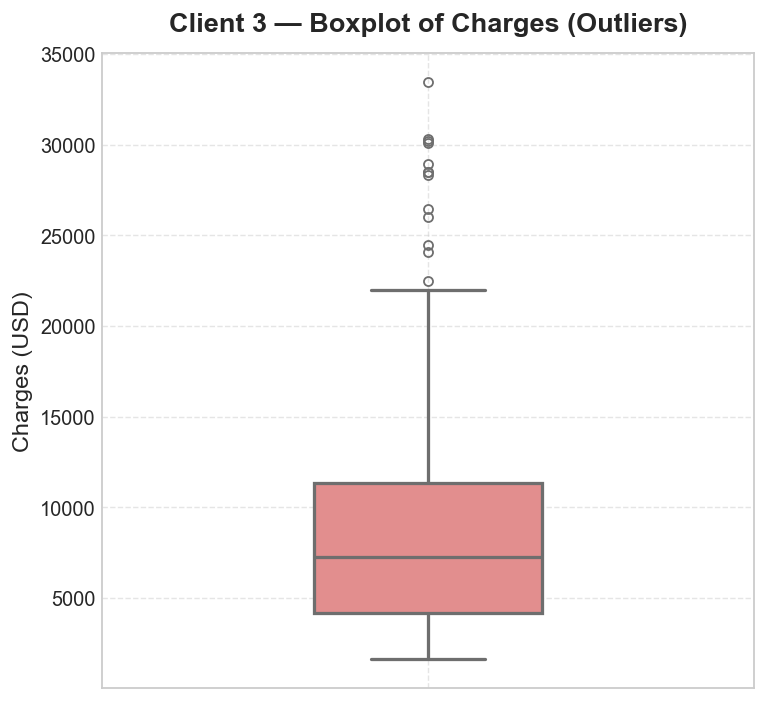

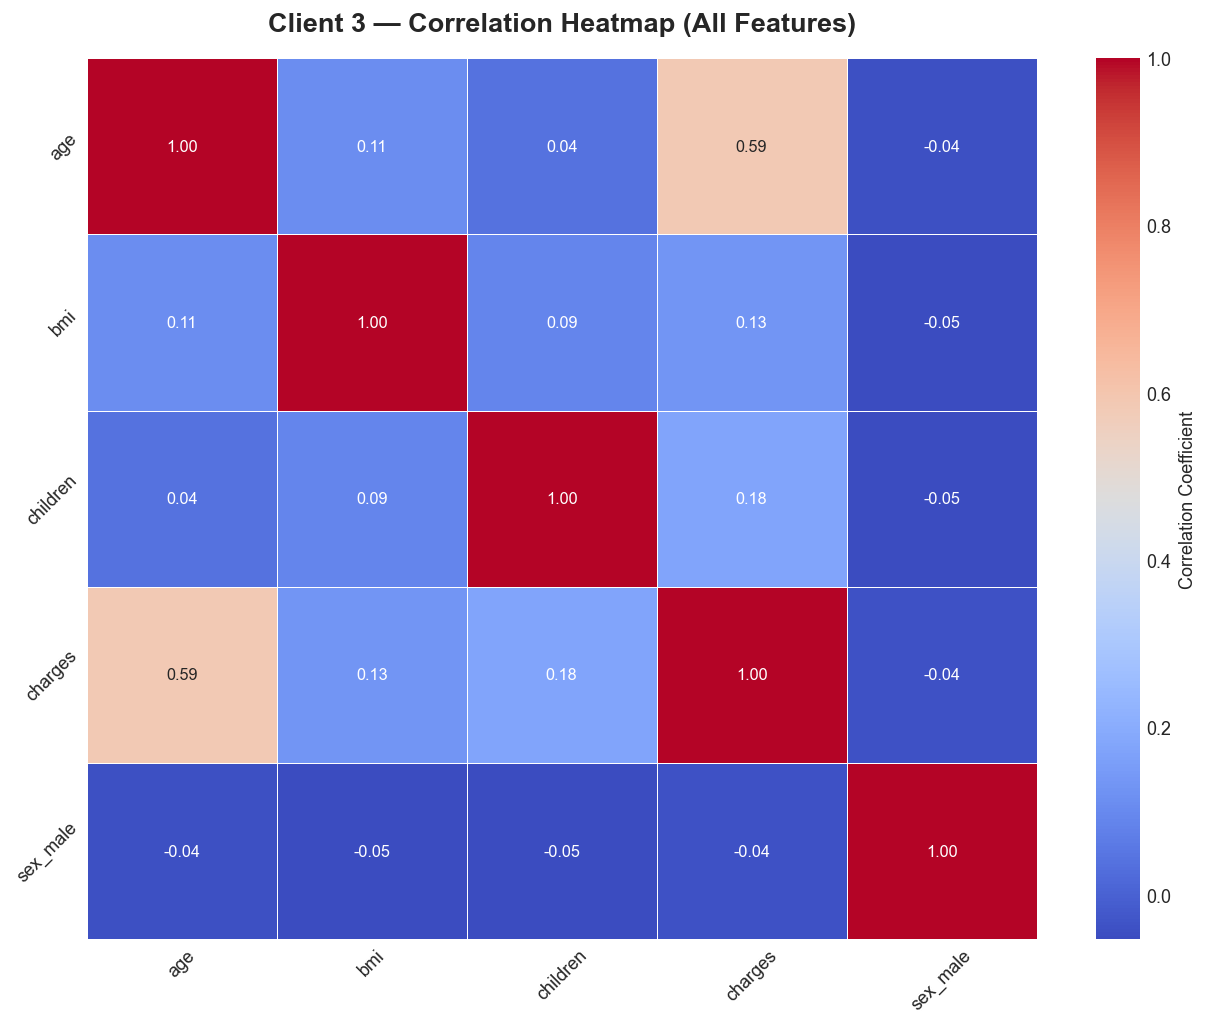


══════════════════════════════════════════════════════════════════════
Client 4 — 58 samples
Region-Smoker group: northwest — yes
Missing values:
 age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Descriptive statistics — Charges:
count       58.00
mean     30192.00
std      11413.83
min      14711.74
25%      20834.13
50%      27489.00
75%      39918.95
max      60021.40
Name: charges, dtype: float64

Categorical proportions:

sex:
sex
male      50.0
female    50.0
Name: proportion, dtype: float64%

smoker:
smoker
yes    100.0
Name: proportion, dtype: float64%

region:
region
northwest    100.0
Name: proportion, dtype: float64%

Correlation of all features with charges (Client 4):
charges     1.000
bmi         0.747
age         0.370
children    0.222
sex_male    0.046
Name: charges, dtype: float64

Client 4 — Mean: $30,192
Client 4 — Median: $27,489
Client 4 — Std: $11,414


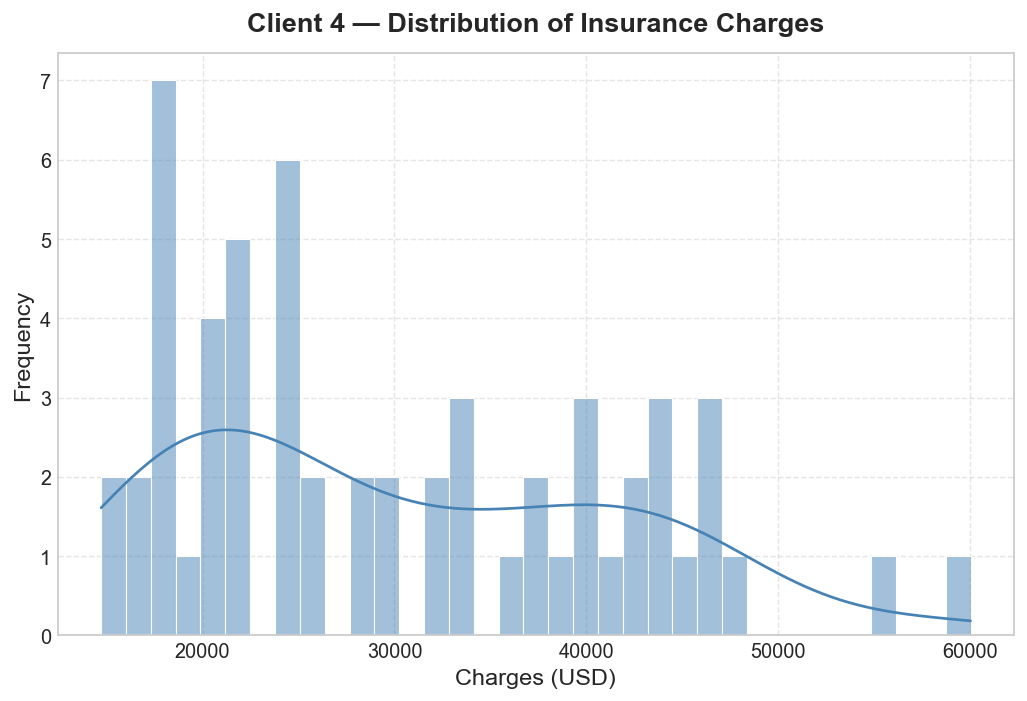

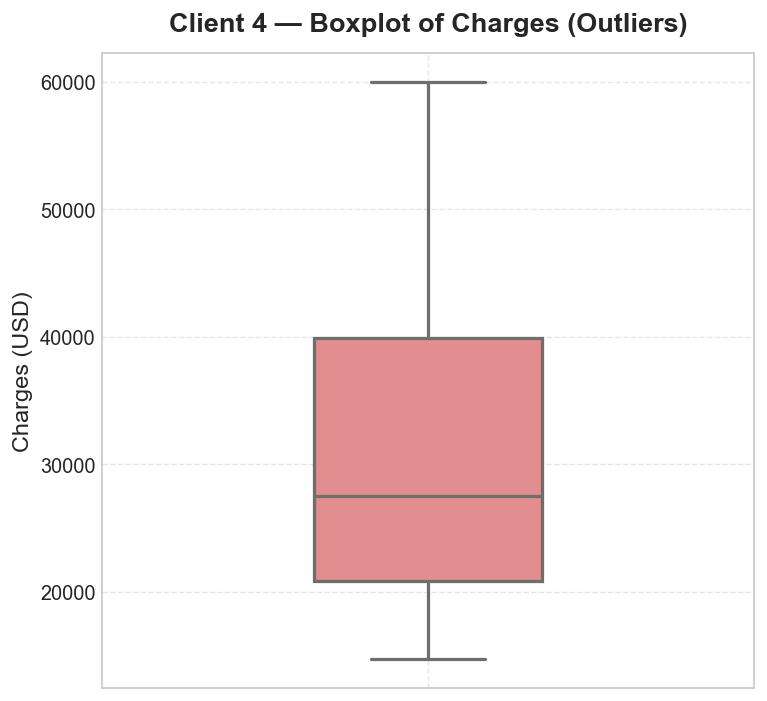

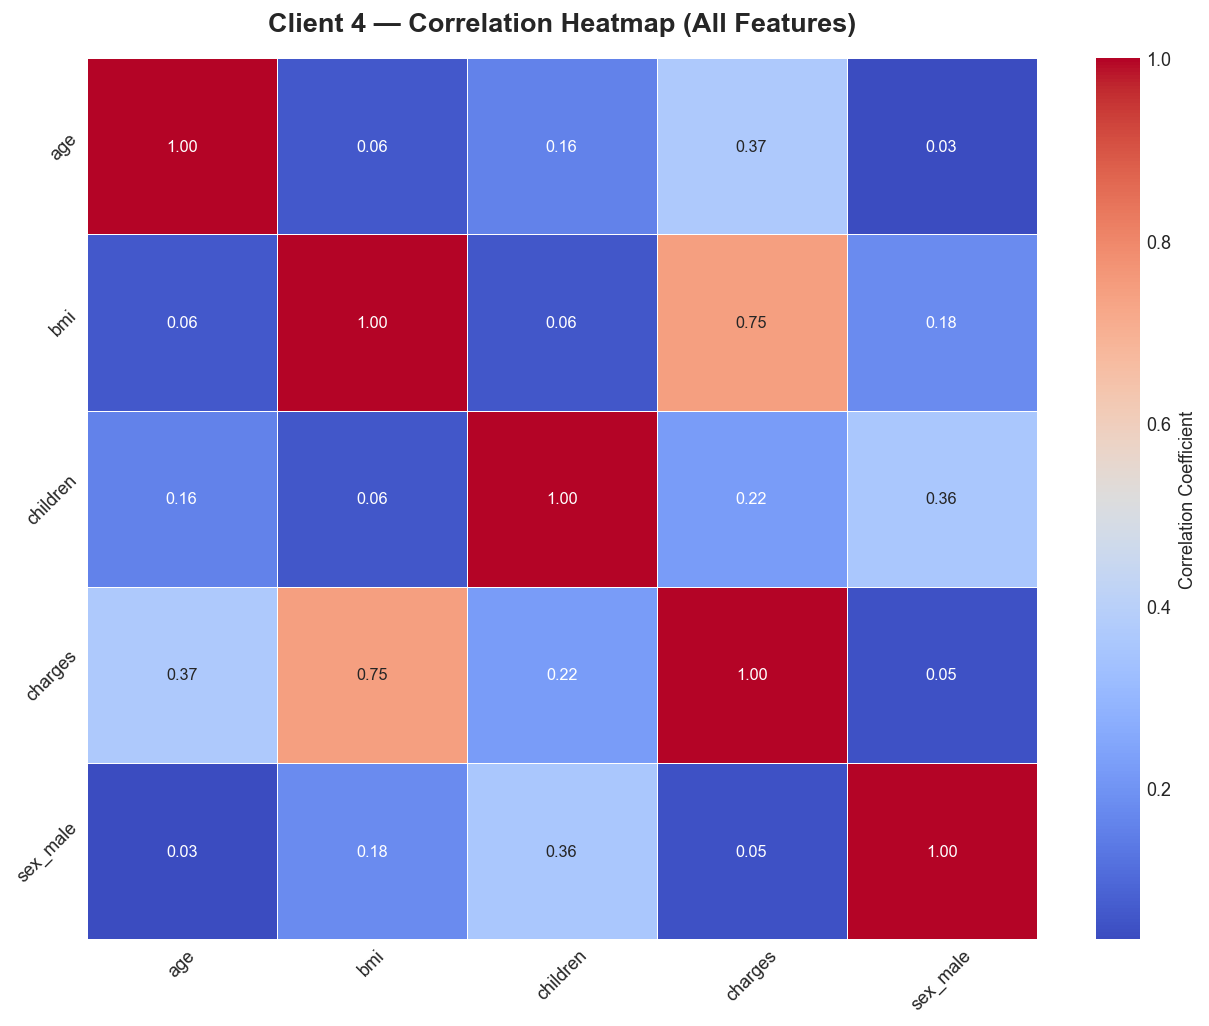


══════════════════════════════════════════════════════════════════════
Client 5 — 273 samples
Region-Smoker group: southeast — no
Missing values:
 age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Descriptive statistics — Charges:
count      273.00
mean      8032.22
std       6137.33
min       1121.87
25%       3471.41
50%       6652.53
75%      10982.50
max      36580.28
Name: charges, dtype: float64

Categorical proportions:

sex:
sex
female    50.9
male      49.1
Name: proportion, dtype: float64%

smoker:
smoker
no    100.0
Name: proportion, dtype: float64%

region:
region
southeast    100.0
Name: proportion, dtype: float64%

Correlation of all features with charges (Client 5):
charges     1.000
age         0.674
children    0.210
bmi        -0.034
sex_male   -0.068
Name: charges, dtype: float64

Client 5 — Mean: $8,032
Client 5 — Median: $6,653
Client 5 — Std: $6,137


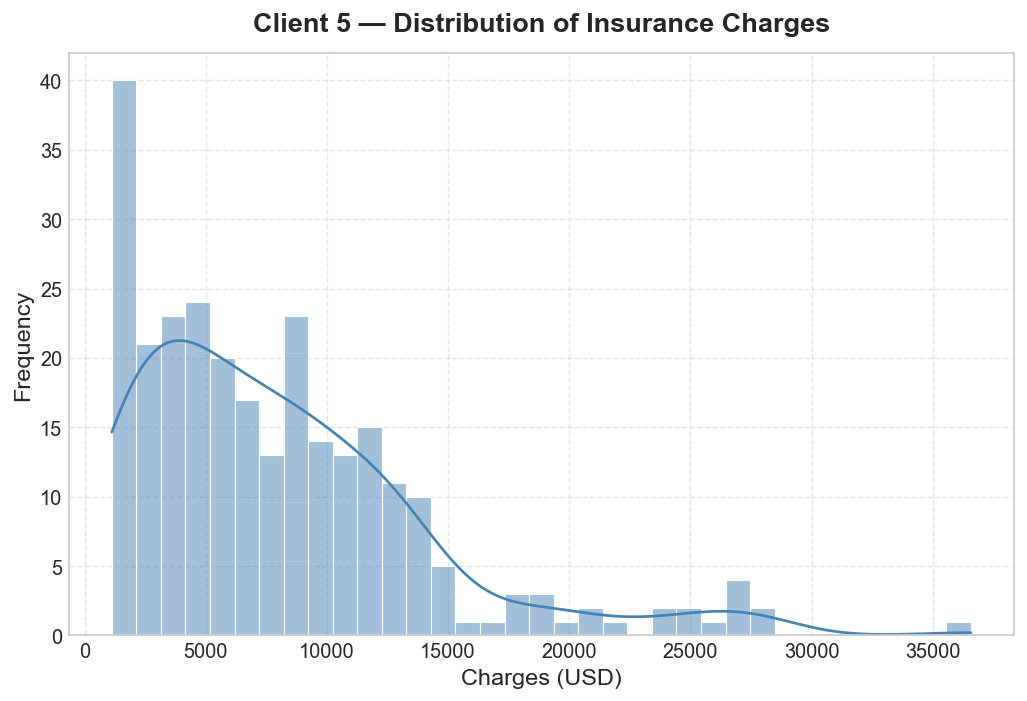

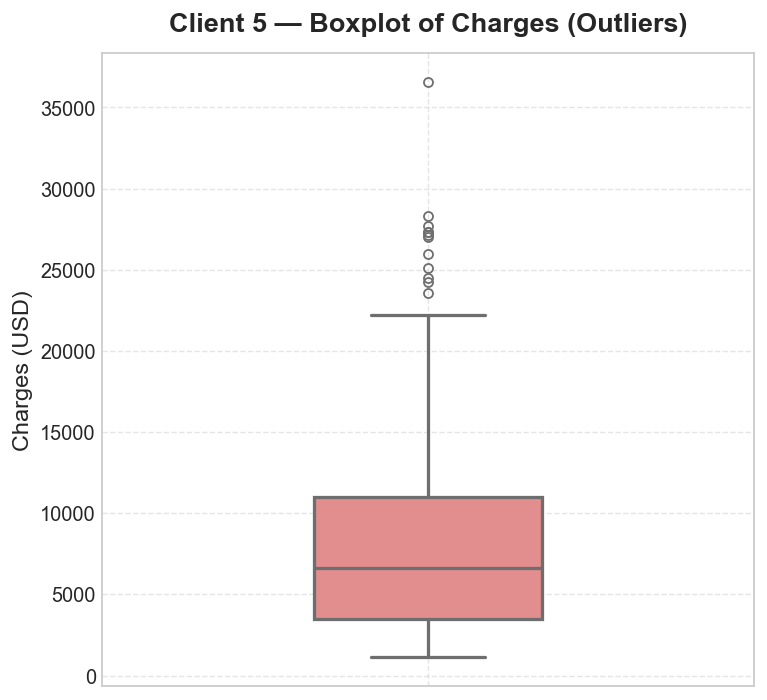

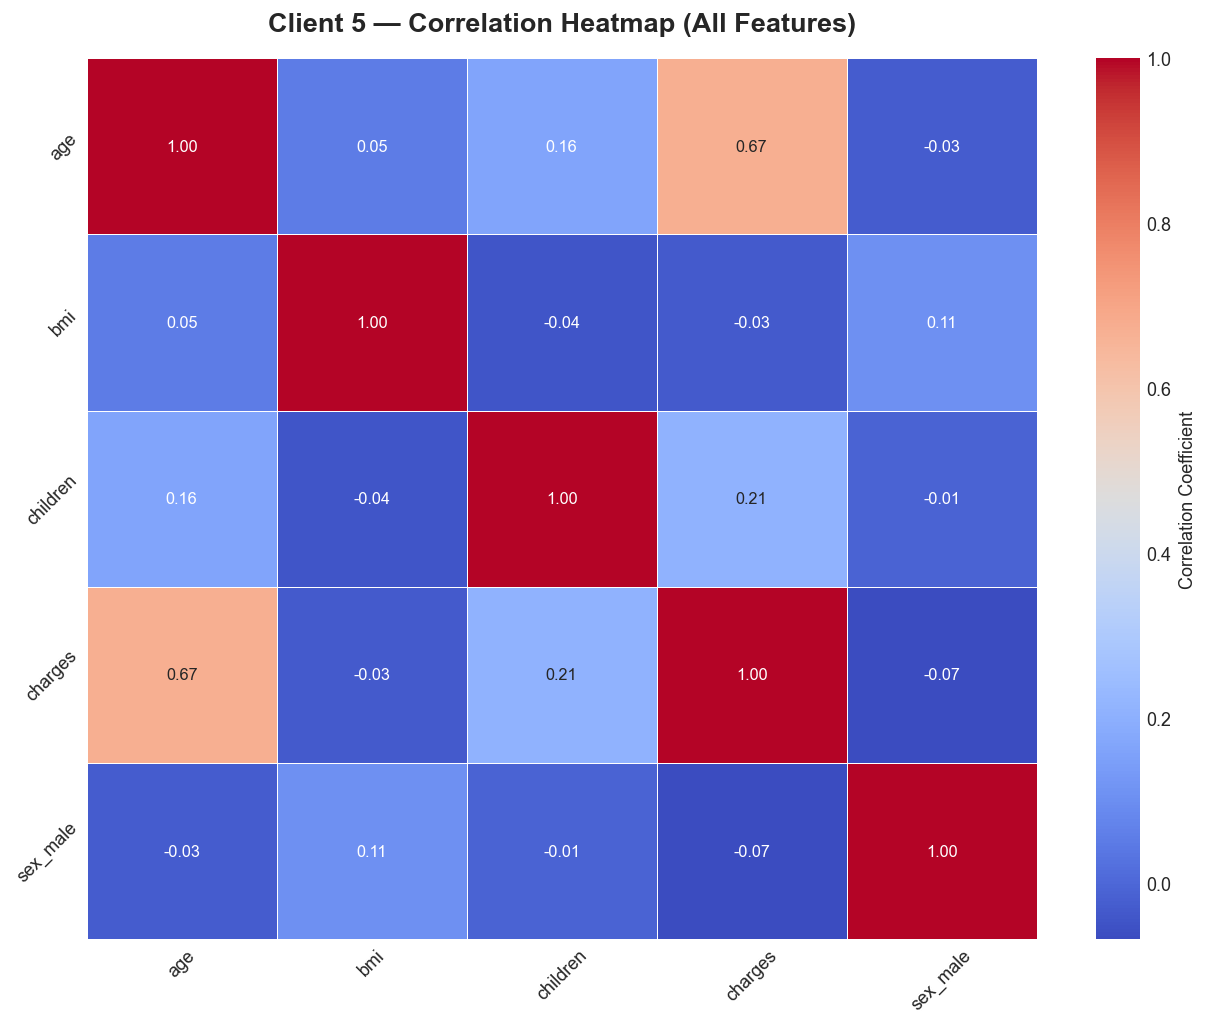


══════════════════════════════════════════════════════════════════════
Total samples across 5 clients: 922


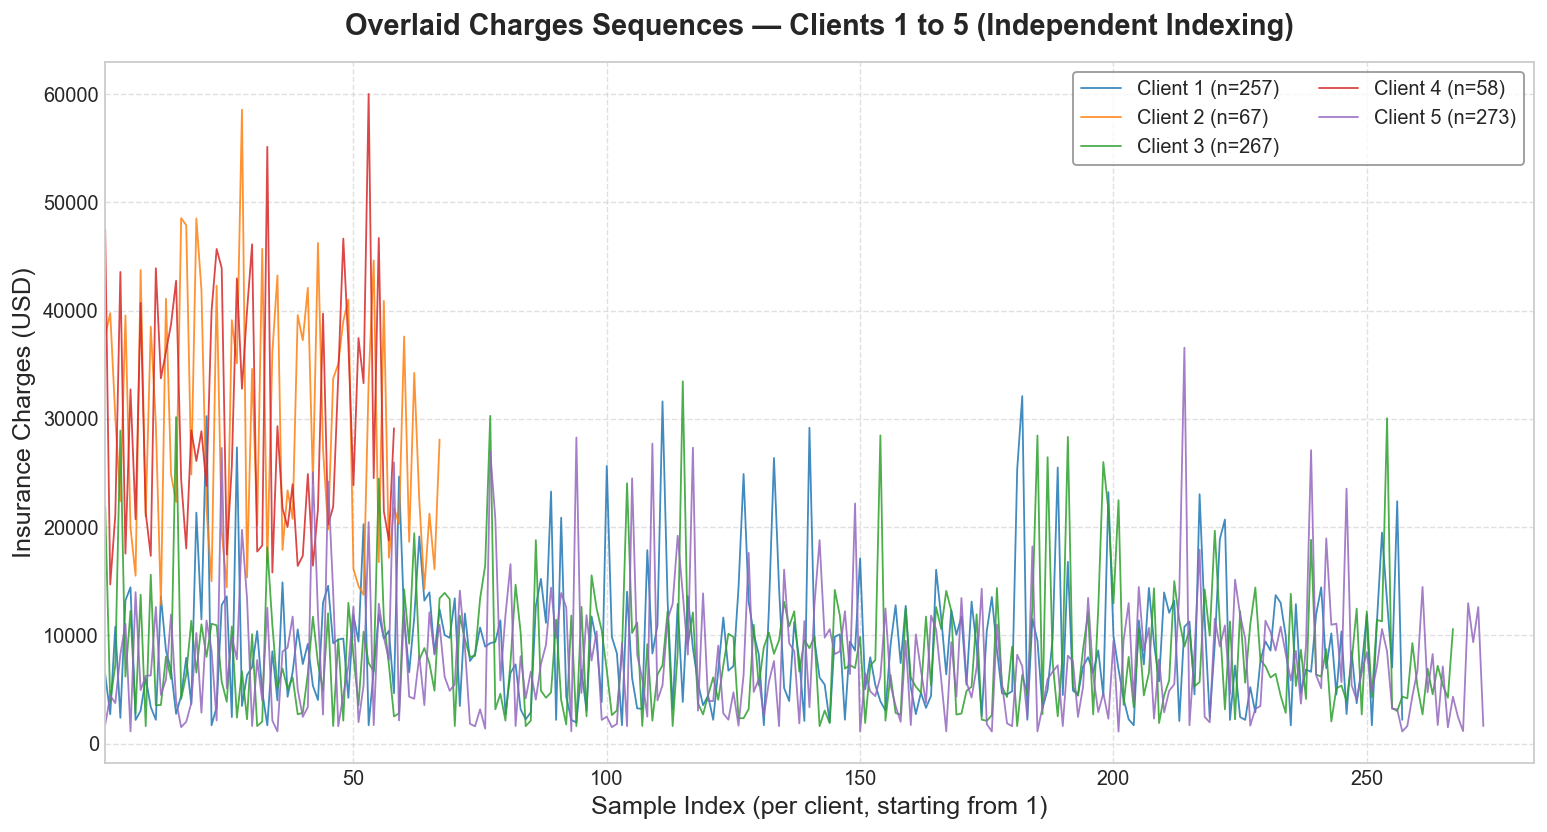

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder

def load_data():
    url = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"
    df = pd.read_csv(url)
    return df

def split_into_clients(df, n_clients=5):
    df_grouped = df.groupby(['region', 'smoker'])
    client_dfs = [group for _, group in df_grouped]
    while len(client_dfs) < n_clients:
        largest = max(client_dfs, key=len)
        client_dfs.remove(largest)
        split_idx = len(largest) // 2
        client_dfs.append(largest.iloc[:split_idx])
        client_dfs.append(largest.iloc[split_idx:])
    return client_dfs[:n_clients]

def encode_categorical(df):
    cat_cols = ['sex', 'smoker', 'region']
    encoder = OneHotEncoder(drop='first', sparse_output=False)
    encoded = encoder.fit_transform(df[cat_cols])
    encoded_df = pd.DataFrame(encoded, columns=encoder.get_feature_names_out(cat_cols), index=df.index)
    numeric_df = df.drop(cat_cols, axis=1)
    return pd.concat([numeric_df, encoded_df], axis=1)

def plot_histogram(client_df, client_id):
    plt.figure(figsize=(8, 5.5), dpi=130)
    sns.histplot(client_df['charges'], kde=True, color='steelblue', bins=35, edgecolor='white', linewidth=0.6)
    plt.title(f"Client {client_id} — Distribution of Insurance Charges", fontsize=15, fontweight='bold', pad=12)
    plt.xlabel("Charges (USD)", fontsize=13)
    plt.ylabel("Frequency", fontsize=13)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tick_params(axis='both', labelsize=11)
    plt.tight_layout()
    plt.show()

def plot_boxplot(client_df, client_id):
    plt.figure(figsize=(6, 5.5), dpi=130)
    sns.boxplot(y=client_df['charges'], color='lightcoral', width=0.35, linewidth=1.8, fliersize=5)
    plt.title(f"Client {client_id} — Boxplot of Charges (Outliers)", fontsize=15, fontweight='bold', pad=12)
    plt.ylabel("Charges (USD)", fontsize=13)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tick_params(axis='y', labelsize=11)
    plt.tight_layout()
    plt.show()

def plot_correlation_heatmap(encoded_df, client_id):
    corr_matrix = encoded_df.corr()
    plt.figure(figsize=(10, 8), dpi=130)
    sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5, 
                cbar_kws={'label': 'Correlation Coefficient'}, annot_kws={'size': 9})
    plt.title(f"Client {client_id} — Correlation Heatmap (All Features)", fontsize=15, fontweight='bold', pad=15)
    plt.tick_params(axis='both', labelsize=10, rotation=45)
    plt.tight_layout()
    plt.show()

def plot_charges_overlaid(client_dfs):
    plt.figure(figsize=(12, 6.5), dpi=130)
    palette = sns.color_palette("tab10", n_colors=5)
    max_length = max(len(c) for c in client_dfs)

    for i, client_df in enumerate(client_dfs, 1):
        indices = np.arange(1, len(client_df) + 1)
        plt.plot(indices, client_df['charges'].values, 
                 label=f"Client {i} (n={len(client_df)})", 
                 color=palette[i-1], 
                 linewidth=1.0, 
                 alpha=0.85)

    plt.xlim(1, max_length + 10)  # beri sedikit ruang di kanan
    plt.xlabel("Sample Index (per client, starting from 1)", fontsize=14, fontweight='medium')
    plt.ylabel("Insurance Charges (USD)", fontsize=14, fontweight='medium')
    plt.title("Overlaid Charges Sequences — Clients 1 to 5 (Independent Indexing)", 
              fontsize=16, fontweight='bold', pad=15)
    plt.legend(loc='upper right', fontsize=11, frameon=True, edgecolor='gray', ncol=2)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tick_params(axis='both', labelsize=11)
    plt.tight_layout()
    plt.show()

def perform_eda_per_client(client_dfs):
    sns.set_style("whitegrid")
    plt.rcParams['font.family'] = 'sans-serif'
    plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']

    for i, client_df in enumerate(client_dfs, 1):
        print("\n" + "═" * 70)
        print(f"Client {i} — {len(client_df)} samples")
        print(f"Region-Smoker group: {client_df['region'].iloc[0]} — {client_df['smoker'].iloc[0]}")
        print("Missing values:\n", client_df.isnull().sum())

        print("\nDescriptive statistics — Charges:")
        print(client_df['charges'].describe().round(2))

        print("\nCategorical proportions:")
        for col in ['sex', 'smoker', 'region']:
            print(f"\n{col}:\n{client_df[col].value_counts(normalize=True).mul(100).round(1)}%")

        encoded = encode_categorical(client_df)
        corr = encoded.corr()['charges'].round(3)
        print(f"\nCorrelation of all features with charges (Client {i}):")
        print(corr.sort_values(ascending=False))

        print(f"\nClient {i} — Mean: ${client_df['charges'].mean():,.0f}")
        print(f"Client {i} — Median: ${client_df['charges'].median():,.0f}")
        print(f"Client {i} — Std: ${client_df['charges'].std():,.0f}")

        plot_histogram(client_df, i)
        plot_boxplot(client_df, i)
        plot_correlation_heatmap(encoded, i)

    print("\n" + "═" * 70)
    print(f"Total samples across 5 clients: {sum(len(c) for c in client_dfs)}")
    plot_charges_overlaid(client_dfs)

if __name__ == "__main__":
    df = load_data()
    client_dfs = split_into_clients(df)
    perform_eda_per_client(client_dfs)